# Tutorial: Mathematical Modelling Group Project (MAC F314)

## First experiments with the FitzHugh–Nagumo model

**Goal.** Use the same two equations to explain three voltage graphs: return to rest, one large spike, and repeated firing.

**Before you start.** You only need to know what a slope is and how to read an $x$–$y$ graph. Run the cells in order. The colored algorithm blocks describe what the Python cells will do.

1. Work out which way voltage and recovery move at one point.
2. Find the state where both variables can stay still.
3. Change the initial voltage or applied current and compare the resulting curves.

The FitzHugh–Nagumo model represents the voltage of an excitable cell and a slower recovery process. Here $v$ is voltage, $w$ is recovery, and $I$ is applied current. The time, state and current use scaled model units. A sharp voltage peak represents a spike-like response. [FitzHugh’s original paper](https://pmc.ncbi.nlm.nih.gov/articles/PMC1366333/)

## 🟦 1. Turn the equations into a Python function

$$
\frac{dv}{dt} = v-\frac{v^3}{3}-w+I,
\qquad
\frac{dw}{dt} = \varepsilon(v+a-bw).
$$

Each equation gives the **slope at the current point**. A positive slope means the variable is rising, and a negative slope means it is falling. Increasing $w$ lowers the voltage slope through the $-w$ term. We use $a=0.7$, $b=0.8$, and $\varepsilon=0.08$ so recovery changes on a slower timescale.

Try the first calculation by hand at $v=w=0$ and $I=0.5$. Then run the cell and compare.

<pre style="background-color: #E7F1FF; color: #17365D; padding: 12px; border-left: 4px solid #2563EB;"><code>MODEL
Read the current voltage v and recovery state w.
Use the two equations to compute their slopes.
Return the voltage slope and the recovery slope.</code></pre>

In [1]:
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import bisect

a, b, epsilon = 0.7, 0.8, 0.08

def fhn(t, state, current):
    # solve_ivp supplies time t. The current is constant in each experiment.
    v, w = state
    dv_dt = v - v**3 / 3 - w + current
    dw_dt = epsilon * (v + a - b * w)
    return dv_dt, dw_dt

voltage_slope, recovery_slope = fhn(0, (0, 0), 0.5)
print(f"At v = w = 0 and I = 0.5: dv/dt = {voltage_slope:.3f}, dw/dt = {recovery_slope:.3f}")
assert abs(voltage_slope - 0.5) < 1e-12
assert abs(recovery_slope - 0.056) < 1e-12

At v = w = 0 and I = 0.5: dv/dt = 0.500, dw/dt = 0.056


## 🟩 2. Find the resting state at zero current

At an **equilibrium**, both slopes are zero. Setting the voltage slope to zero gives $w=v-v^3/3+I$. Setting the recovery slope to zero gives $w=(v+a)/b$. These two curves are called **nullclines**. Their intersection gives the equilibrium.

Substituting the second expression into the first gives

$$
\frac{b}{3}v_*^3+(1-b)v_*+a-bI=0.
$$

We search for the root at $I=0$. **Bisection** repeatedly halves an interval whose endpoints have opposite signs. Each step keeps the half containing the sign change. At our chosen $b$, the cubic is strictly increasing, so the root is unique.

<pre style="background-color: #E8F7ED; color: #15432B; padding: 12px; border-left: 4px solid #27804E;"><code>REST
Find the voltage where the cubic is zero at I = 0.
Use that voltage to compute the recovery state.
Substitute both values into the original slope equations.</code></pre>

In [2]:
def resting_cubic(v):
    # This is the equilibrium equation with I = 0.
    return (b / 3) * v**3 + (1 - b) * v + a

rest_v = bisect(resting_cubic, -3.0, 3.0)
rest_w = (rest_v + a) / b

# Both slopes must be essentially zero at an equilibrium.
assert all(abs(slope) < 1e-10 for slope in fhn(0, (rest_v, rest_w), 0.0))
print(f"Zero-current equilibrium: v = {rest_v:.4f}, w = {rest_w:.4f}")

Zero-current equilibrium: v = -1.1994, w = -0.6243


## 🟨 3. Run three experiments

The solver uses the slopes to estimate how $v$ and $w$ change over time. We ask it to report 1,501 points from time 0 to 150. The solver chooses its own internal steps to control numerical error. [SciPy’s integration guide](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html)

| Run | Initial voltage | Applied current |
| --- | --- | --- |
| Small nudge | Resting voltage plus $0.05$ | $I=0$ throughout |
| Larger nudge | Resting voltage plus $0.90$ | $I=0$ throughout |
| Sustained input | Same starting voltage as the small nudge | $I=0.50$ throughout |

In all three runs, recovery starts at the same value $w_*$. The nudges are changes to the initial voltage. The current in the third run stays on for the full simulation.

<pre style="background-color: #FFF3D4; color: #503300; padding: 12px; border-left: 4px solid #B56A00;"><code>SIMULATE
Choose the starting voltage and the constant current.
Start recovery at its zero-current equilibrium value.
Integrate the two equations and keep the resulting voltage curve.</code></pre>

In [3]:
times = [step / 10 for step in range(1501)]

def simulate(initial_voltage, current, *, rtol=1e-9, atol=1e-11):
    # args passes the same applied current to every evaluation of fhn.
    solution = solve_ivp(
        fhn,
        (times[0], times[-1]),
        (initial_voltage, rest_w),
        args=(current,),
        t_eval=times,
        method="DOP853",
        rtol=rtol,
        atol=atol,
    )
    if not solution.success:
        raise RuntimeError(solution.message)
    # solution.y[0] is voltage and solution.y[1] is recovery.
    return solution.y

small_nudge = simulate(rest_v + 0.05, 0.0)
large_nudge = simulate(rest_v + 0.90, 0.0)
sustained = simulate(rest_v + 0.05, 0.50)

## 🟪 4. Plot the responses on the same scale

All three plots use the same voltage scale so their peaks can be compared directly. The dashed line marks the **zero-current resting voltage**, which is a reference for the two nudge experiments.

<pre style="background-color: #F1EAFE; color: #38205C; padding: 12px; border-left: 4px solid #7547B2;"><code>COMPARE
Plot time along the bottom and voltage up the side.
Use the same axis limits for each experiment.
Look for a return to rest, one spike, and repeated spikes.</code></pre>

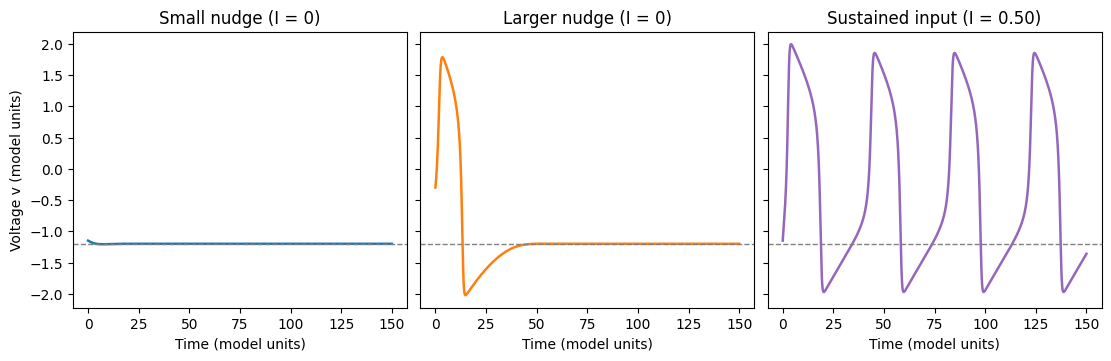

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5), sharex=True, sharey=True, layout="constrained")
traces = [
    (small_nudge[0], "Small nudge (I = 0)", "tab:blue"),
    (large_nudge[0], "Larger nudge (I = 0)", "tab:orange"),
    (sustained[0], "Sustained input (I = 0.50)", "tab:purple"),
]

for ax, (voltage, title, color) in zip(axes, traces):
    # Shared axes make the three spike heights directly comparable.
    ax.plot(times, voltage, color=color, linewidth=1.8)
    ax.axhline(rest_v, color="0.5", linestyle="--", linewidth=1)
    ax.set(title=title, xlabel="Time (model units)")

axes[0].set_ylabel("Voltage v (model units)")
plt.show()

**Reading the plots.** The small nudge fades. The larger nudge produces a single spike and still returns to the same resting level. With current kept on, the model produces repeated spikes. The plot on the right is a starting point for studying how the long-term behaviour changes as we vary $I$.

## 🟧 5. Check the result

For these particular traces, count a spike when voltage crosses zero **upward**. Check that the two zero-current runs return to rest and that the firing result persists when we tighten the solver tolerances.

<pre style="background-color: #FFEDE3; color: #522915; padding: 12px; border-left: 4px solid #B55223;"><code>VERIFY
Count upward crossings of zero.
Check that the two nudges return to the resting voltage.
Repeat the sustained-current run with tighter tolerances.</code></pre>

In [5]:
def count_spikes(voltage):
    # Count the first non-negative sample after a negative sample.
    return sum(before < 0 <= after for before, after in zip(voltage[:-1], voltage[1:]))

assert count_spikes(small_nudge[0]) == 0
assert count_spikes(large_nudge[0]) == 1
assert count_spikes(sustained[0]) >= 3
assert abs(small_nudge[0, -1] - rest_v) < 1e-6
assert abs(large_nudge[0, -1] - rest_v) < 1e-6

# Compare both state variables on the same output grid.
tighter = simulate(rest_v + 0.05, 0.50, rtol=1e-11, atol=1e-13)
largest_difference = abs(sustained - tighter).max()
assert largest_difference < 1e-6
print(f"Spike counts: {count_spikes(small_nudge[0])}, {count_spikes(large_nudge[0])}, {count_spikes(sustained[0])}")
print(f"Numerical checks passed. Largest change with tighter tolerances: {largest_difference:.2e}")

Spike counts: 0, 1, 4
Numerical checks passed. Largest change with tighter tolerances: 4.39e-08


### Quick exercise

What happens to the voltage and recovery slopes at $v=0$, $w=0.5$, and $I=0.5$? Work it out by hand, then compare with the answer.

<details>
<summary>Show answer</summary>

The voltage slope is $0-0-0.5+0.5=0$. The recovery slope is $0.08(0.7-0.8\times0.5)=0.024$. The point lies on the voltage nullcline, and recovery is still changing. An equilibrium requires both slopes to vanish.

</details>

**Next experiment.** Plot voltage against recovery and mark the two nullclines. Then use the Jacobian to explain the response to a small disturbance near equilibrium.